# Preprocessing B - Signed I/Q Representation for V5

This notebook defines the alternative signal representation evaluated only by model V5. Versions V1-V4 use the magnitude pipeline documented in `03a_preprocessing_magnitude.ipynb`. V5 preserves signed I and Q values as separate channels to test whether antenna phase relationships improve multi-person 2D localisation.

## 1. Experimental rationale

Magnitude preprocessing computes `sqrt(I^2 + Q^2)`. It is compact and stable but removes sign and quadrature relationships. The dataset contains three antennas per radar specifically to provide angular diversity. V5 therefore keeps `[I0, Q0, I1, Q1, I2, Q2]` as six channels per radar.

The experiment remains controlled: train/validation windows, coordinate clipping, target construction, model architecture, loss, and evaluator are unchanged from V2.

In [1]:
%matplotlib inline

import getpass
import importlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import preprocessing as preprocessing_module
preprocessing_module = importlib.reload(preprocessing_module)
from preprocessing import PreprocessingConfig, transform_signed_iq_channels

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])

ARTIFACT_DIR = SRC_DIR / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
with (ARTIFACT_DIR / 'data_split.json').open(encoding='utf-8') as handle:
    split = json.load(handle)
TRAIN_WINDOWS = split['train_windows']
VALIDATION_WINDOWS = split['validation_windows']
REPO_ID = 'HAEEAI/multi-person-localization'
CHUNK_SIZE = 256

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti


## 2. Resolve the same acquisition windows

The fixed split produced by Preprocessing A is reused exactly. Hugging Face returns cached files when available.

In [2]:
window_paths = {}
for index in sorted(TRAIN_WINDOWS + VALIDATION_WINDOWS):
    filename = f'data/window_{index:06d}.npz'
    window_paths[index] = Path(hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    ))
print(f'{len(window_paths)} windows are ready.')

24 windows are ready.


## 3. Signed I/Q transformation

Each signed component is compressed as `sign(value) * log(1 + abs(value))`. This reduces dynamic range while retaining sign. The tensor is rearranged from `(T, radar, antenna, bin, I/Q)` to `(T, radar, six_channels, bin)`.

In [3]:
SIGNED_IQ_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5),
    antenna_mode='none',
    range_bin_start=0,
    range_bin_stop=120,
    log_compression=True,
    background_mode='none',
)
with np.load(window_paths[TRAIN_WINDOWS[0]], allow_pickle=False) as data:
    example_iq = np.asarray(data['radar_cir_iq'][:250])
example_features = transform_signed_iq_channels(example_iq, SIGNED_IQ_CONFIG)
assert example_features.shape == (250, 6, 6, 120)
assert np.isfinite(example_features).all()
print('Signed I/Q example shape:', example_features.shape)

Signed I/Q example shape: (250, 6, 6, 120)


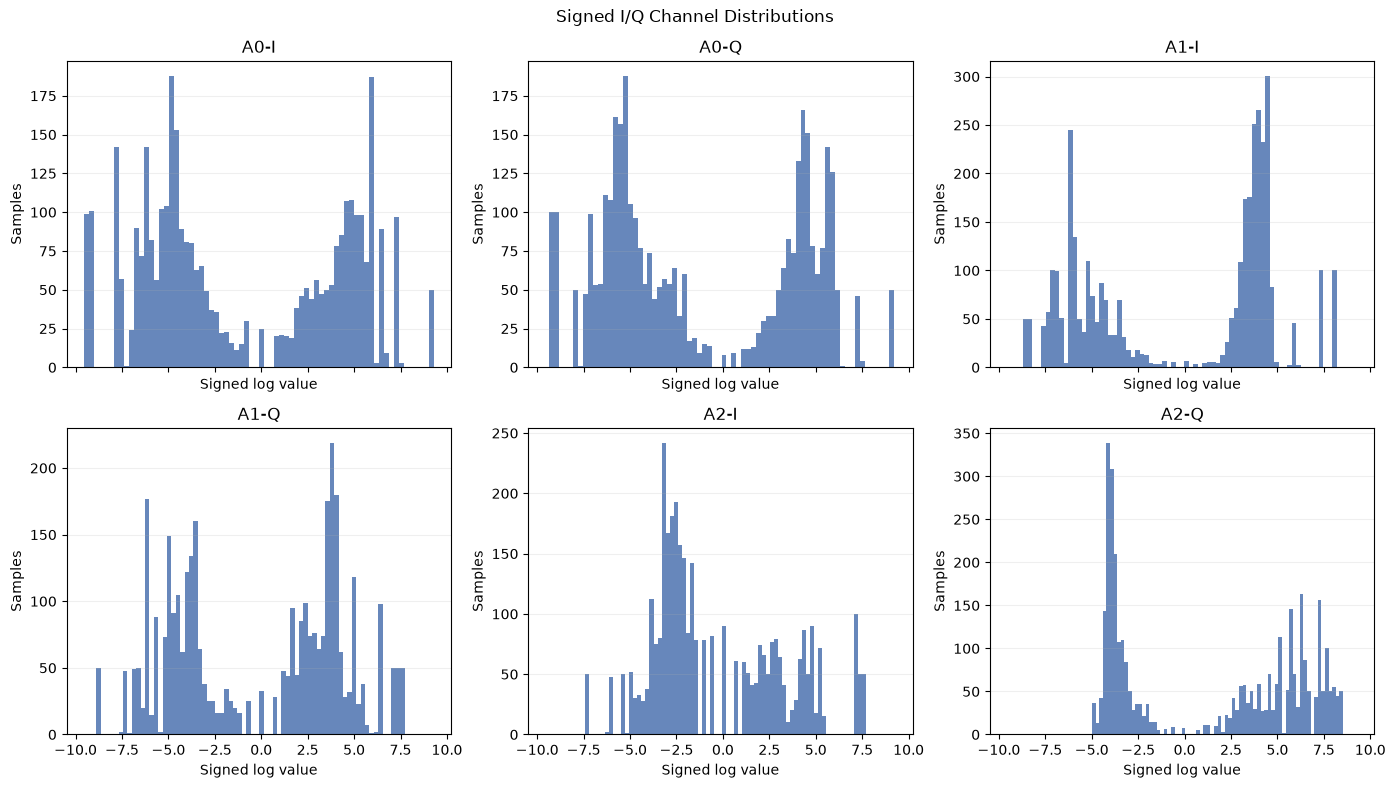

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
channel_names = ['A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q']
for channel, axis in enumerate(axes.flat):
    values = example_features[:, :, channel, :].ravel()[::50]
    axis.hist(values, bins=70, color='#4c72b0', alpha=0.85)
    axis.set(title=channel_names[channel], xlabel='Signed log value', ylabel='Samples')
    axis.grid(axis='y', alpha=0.2)
fig.suptitle('Signed I/Q Channel Distributions')
plt.tight_layout()
plt.show()

## 4. Train-only radar/channel statistics

A separate mean and standard deviation are estimated for every radar/channel pair, producing 6x6 matrices. Statistics are streamed in 256-frame blocks and use only the 19 training windows.

In [5]:
total_sum = np.zeros((6, 6), dtype=np.float64)
total_square_sum = np.zeros((6, 6), dtype=np.float64)
total_values = 0
for position, index in enumerate(TRAIN_WINDOWS, start=1):
    print(f'[{position:02d}/{len(TRAIN_WINDOWS):02d}] Statistics from window {index:06d}')
    with np.load(window_paths[index], allow_pickle=False) as data:
        radar = data['radar_cir_iq']
        for start in range(0, len(radar), CHUNK_SIZE):
            block = transform_signed_iq_channels(radar[start:start + CHUNK_SIZE], SIGNED_IQ_CONFIG)
            total_sum += block.sum(axis=(0, 3), dtype=np.float64)
            total_square_sum += np.square(block, dtype=np.float64).sum(axis=(0, 3))
            total_values += block.shape[0] * block.shape[3]
IQ_MEAN = (total_sum / total_values).astype(np.float32)
variance = np.maximum(total_square_sum / total_values - IQ_MEAN.astype(np.float64) ** 2, 0.0)
IQ_STD = np.sqrt(variance).astype(np.float32)
assert IQ_MEAN.shape == IQ_STD.shape == (6, 6)
assert np.all(IQ_STD > 0)
print('Mean range:', float(IQ_MEAN.min()), float(IQ_MEAN.max()))
print('Std range:', float(IQ_STD.min()), float(IQ_STD.max()))

[01/19] Statistics from window 000000
[02/19] Statistics from window 000001
[03/19] Statistics from window 000002
[04/19] Statistics from window 000004
[05/19] Statistics from window 000005
[06/19] Statistics from window 000006
[07/19] Statistics from window 000007
[08/19] Statistics from window 000008
[09/19] Statistics from window 000010
[10/19] Statistics from window 000011
[11/19] Statistics from window 000012
[12/19] Statistics from window 000013
[13/19] Statistics from window 000015
[14/19] Statistics from window 000016
[15/19] Statistics from window 000017
[16/19] Statistics from window 000019
[17/19] Statistics from window 000020
[18/19] Statistics from window 000021
[19/19] Statistics from window 000022
Mean range: -1.485499620437622 1.4447245597839355
Std range: 3.7532403469085693 5.646988391876221


## 5. Validation-distribution check

Validation means and standard deviations are measured without updating the training statistics. Large deviations would indicate that signed I/Q is more session-sensitive than magnitude.

In [6]:
validation_summary = []
for index in VALIDATION_WINDOWS:
    value_sum = value_square_sum = 0.0
    value_count = 0
    maximum = 0.0
    with np.load(window_paths[index], allow_pickle=False) as data:
        radar = data['radar_cir_iq']
        for start in range(0, len(radar), CHUNK_SIZE):
            block = transform_signed_iq_channels(radar[start:start + CHUNK_SIZE], SIGNED_IQ_CONFIG)
            normalised = (block - IQ_MEAN[None, :, :, None]) / (IQ_STD[None, :, :, None] + 1e-6)
            value_sum += float(normalised.sum(dtype=np.float64))
            value_square_sum += float(np.square(normalised, dtype=np.float64).sum())
            value_count += normalised.size
            maximum = max(maximum, float(np.max(np.abs(normalised))))
    mean = value_sum / value_count
    std = np.sqrt(max(value_square_sum / value_count - mean**2, 0.0))
    validation_summary.append((index, mean, std, maximum))
print('Window | Mean | Std | Maximum absolute value')
for index, mean, std, maximum in validation_summary:
    print(f'{index:>6} | {mean:>7.4f} | {std:>7.4f} | {maximum:>8.4f}')

Window | Mean | Std | Maximum absolute value
     3 |  0.0163 |  1.0195 |   2.4615
     9 |  0.0043 |  0.9896 |   2.4711
    14 |  0.0014 |  0.9929 |   2.4679
    18 | -0.0052 |  0.9997 |   2.5213
    23 | -0.0075 |  0.9981 |   2.5214


## 6. Save the V5 preprocessing contract

The training notebook loads this artifact and does not recompute statistics. The final inference script must use exactly the same channel order, signed-log transform, and constants.

In [7]:
artifact = {
    'representation': 'signed_iq',
    'config': {
        'radar_indices': list(V5_CONFIG.radar_indices),
        'antenna_mode': V5_CONFIG.antenna_mode,
        'range_bin_start': V5_CONFIG.range_bin_start,
        'range_bin_stop': V5_CONFIG.range_bin_stop,
        'log_compression': V5_CONFIG.log_compression,
        'background_mode': V5_CONFIG.background_mode,
        'ema_alpha': V5_CONFIG.ema_alpha,
        'epsilon': V5_CONFIG.epsilon,
    },
    'channel_order': ['A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q'],
    'input_shape': [6, 6, 120],
    'transform': 'sign(x) * log1p(abs(x))',
    'mean': IQ_MEAN.tolist(),
    'std': IQ_STD.tolist(),
    'training_windows': TRAIN_WINDOWS,
    'validation_windows': VALIDATION_WINDOWS,
}
output_path = ARTIFACT_DIR / 'v5_iq_normalization.json'
with output_path.open('w', encoding='utf-8') as handle:
    json.dump(artifact, handle, indent=2)
print('Saved:', output_path.resolve())

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v5_iq_normalization.json


## 7. Conclusions and technical implications

Preprocessing B preserves phase-related I/Q cues while retaining the fixed data split and target policy. It doubles the input from 2,160 to 4,320 values, corresponding to approximately 4.2 KiB in INT8. The first convolution output shape is unchanged, so the dominant early activation does not grow. Only the first convolution kernel receives additional input channels.

This contract is used only by V5. V1-V4 remain tied to the magnitude artifact from Preprocessing A. If V5 fails to improve global Hungarian F1 over V2, signed I/Q will be retained as a documented negative experiment and V2 will proceed to full INT8 conversion.